# **Laboratorio Calificado N.° 07 | Analítica Empresarial Integrada**
**TECSUP · 2026-II**  
**Gobierno de datos, cumplimiento e IA generativa**  
**Docente: Pilar Rocío Sayán Mejía.**

**Equipo:**
- Arias Zevallos, Anthony Henry
- Arteaga Guerra, Pedro Sebastian Alfieri
- Furushio Casanave, Piero Hideki
- Salazar Chavez, Renzo Sebastian

## **Caso:**
El área de riesgos de una entidad financiera requiere evaluar la viabilidad de implementar un modelo predictivo de incumplimiento crediticio y un asistente de inteligencia artificial generativa que transforme preguntas en lenguaje natural en consultas SQL.

## **Objetivo:**

Evaluar el desempeño, la equidad, la explicabilidad, la seguridad y los controles de gobierno de ambas herramientas, con la finalidad de formular recomendaciones sustentadas en evidencia cuantitativa para la dirección del área de riesgos.

## **Alcance:**
El laboratorio comprende seis ejercicios:

- Ficha de datos, calidad y gobierno.

- Modelo predictivo y auditoría por subgrupos.

- Explicabilidad, controles y hallazgos.

- Construcción y seguridad del asistente Text-to-SQL.

- Evaluación del asistente y mitigación.

- Decisión integrada y análisis de sensibilidad.

## **Fuente de información:**

Se utiliza el conjunto de datos Default of Credit Card Clients del repositorio UCI Machine Learning Repository (ID 350), compuesto por 30 000 registros históricos de clientes de tarjetas de crédito de una entidad financiera de Taiwán durante el año 2005.


In [ ]:
# Decisión: instalar las dependencias del laboratorio; sin estas no se reproduce el flujo.
%pip -q install ucimlrepo duckdb sqlglot shap openai xlrd

In [ ]:
# Decisión: fijar semilla y criterios ANTES de observar resultados para evitar acomodarlos.
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix, accuracy_score, r2_score
from sklearn.ensemble import RandomForestRegressor
import warnings, hashlib, json, re
SEED = 2026
THRESHOLDS = [0.30, 0.50, 0.70]
MIN_GROUP, MIN_CLASS = 100, 20
# Criterios académicos propuestos, no límites legales ni estándares bancarios.
MODEL_AUC_MIN, MODEL_RECALL_MIN, MODEL_FPR_MAX = .70, .40, .30
GAP_MAX, GAP_HARD = .10, .20
SQL_USE, SQL_COND = 1.0, .75
# No hay evidencia organizacional adjunta; no confundir un notebook con un control implementado.
ORG = {'acceso': False, 'supervision': False, 'finalidad_legal': False}
# Cambiar solo si el equipo obtiene evidencia verificable ANTES de aplicar la regla.

# Ejercicio 1 — Ficha de datos, calidad y gobierno
Fuente: Yeh, I.-C. (2009). *Default of Credit Card Clients*, UCI, ID 350, DOI [10.24432/C55S3H](https://doi.org/10.24432/C55S3H). Datos históricos de Taiwán, abril–septiembre de 2005; objetivo: incumplimiento del siguiente mes (1 = sí, 0 = no). Finalidad académica: estimar riesgo y auditar posibles brechas, no decidir créditos reales. Propietario propuesto: Dirección de Riesgos; custodio: equipo de ingeniería de datos; acceso real y base jurídica no evidenciados.

Linaje: descarga oficial → normalización de nombres (PAY_0 se denomina pay_1) → controles y conservación de registros → partición estratificada → transformación ajustada solo en entrenamiento → modelo → predicciones de prueba → auditoría/SHAP. En paralelo: datos normalizados → DuckDB → contexto → LLM → validación → ejecución restringida → comparación con referencias.

In [ ]:
# Decisión: descargar el archivo oficial, preservar valores y registrar hash; sin ello falta trazabilidad.
from urllib.request import urlopen
from io import BytesIO
from zipfile import ZipFile
URL = 'https://archive.ics.uci.edu/static/public/350/default%2Bof%2Bcredit%2Bcard%2Bclients.zip'
with urlopen(URL, timeout=90) as r:
    raw_zip = r.read()
with ZipFile(BytesIO(raw_zip)) as z:
    name = next(x for x in z.namelist() if x.lower().endswith('.xls') and not x.startswith('__MACOSX'))
    raw = pd.read_excel(BytesIO(z.read(name)), header=1, engine='xlrd')
fecha_descarga = datetime.now(timezone.utc).isoformat()
df = raw.copy()
def norm(s): return re.sub(r'[^a-z0-9]+','_',str(s).lower()).strip('_')
df.columns = [norm(x) for x in df.columns]
df = df.rename(columns={'pay_0':'pay_1','default_payment_next_month':'default'})
# Homogeneizar nombres de montos sin modificar los datos.
df = df.rename(columns={**{f'bill_amt{i}':f'bill_amt_{i}' for i in range(1,7)}, **{f'pay_amt{i}':f'pay_amt_{i}' for i in range(1,7)}})
paycols = [f'pay_{i}' for i in range(1,7)]
billcols = [f'bill_amt_{i}' for i in range(1,7)]
amountcols = [f'pay_amt_{i}' for i in range(1,7)]
expected = ['id','limit_bal','sex','education','marriage','age']+paycols+billcols+amountcols+['default']
assert set(df.columns)==set(expected), df.columns.tolist()
df = df[expected].apply(pd.to_numeric, errors='raise')
assert df.shape == (30000,25) and df.id.is_unique and df.id.notna().all()
assert set(df.default.unique()) == {0,1}
assert df.isna().sum().sum()==0, 'Revisar nulos antes de continuar'
print('Descarga UTC:',fecha_descarga,'| SHA256:',hashlib.sha256(raw_zip).hexdigest())
print('Dimensiones:',df.shape,'| Incumplimientos:',int(df.default.sum()),'| Tasa base:',f'{df.default.mean():.2%}')
display(df.head(3).drop(columns='id'))

Descarga UTC: 2026-11-21T03:42:40.848618+00:00 | SHA256: 56c885f84457f6680f8438f02bfcdac9579323d8a94465ee5f26e32baa727602
Dimensiones: (30000, 25) | Incumplimientos: 6636 | Tasa base: 22.12%


,limit_bal,sex,education,marriage,age,pay_1,pay_2,pay_3,pay_4,pay_5,...,bill_amt_4,bill_amt_5,bill_amt_6,pay_amt_1,pay_amt_2,pay_amt_3,pay_amt_4,pay_amt_5,pay_amt_6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


In [ ]:
# Decisión: contar valores no definidos respecto al diccionario UCI y duplicados sin borrar clientes.
# Eliminar automáticamente podría alterar prevalencia y representación de los grupos.
valid_codes = {'education':{1,2,3,4},'marriage':{1,2,3}, **{c:{-1,*range(1,10)} for c in paycols}}
quality = []
for c, valid in valid_codes.items():
    bad = df.loc[~df[c].isin(valid),c]
    quality.append({'variable':c,'n_no_definidos':len(bad),'porcentaje':100*len(bad)/len(df),'detalle':bad.value_counts().sort_index().to_dict()})
quality = pd.DataFrame(quality)
cols_no_id = df.columns.drop('id').tolist()
duplicados = int(df.duplicated(subset=cols_no_id).sum())
duplicados_todos = int(df.duplicated(subset=cols_no_id,keep=False).sum())
display(quality)
print('Duplicados adicionales sin id (incluye objetivo):',duplicados,'| filas involucradas:',duplicados_todos)
print('Duplicados de predictores sin id ni objetivo:',df.duplicated(subset=[c for c in cols_no_id if c!='default']).sum())
print('Nulos:',int(df.isna().sum().sum()),'| edad mínima y máxima:',df.age.min(),df.age.max())

,variable,n_no_definidos,porcentaje,detalle
0,education,345,1.150000,"{0: 14, 5: 280, 6: 51}"
1,marriage,54,0.180000,{0: 54}
2,pay_1,17496,58.320000,"{-2: 2759, 0: 14737}"
3,pay_2,19512,65.040000,"{-2: 3782, 0: 15730}"
4,pay_3,19849,66.163333,"{-2: 4085, 0: 15764}"
5,pay_4,20803,69.343333,"{-2: 4348, 0: 16455}"
6,pay_5,21493,71.643333,"{-2: 4546, 0: 16947}"
7,pay_6,21181,70.603333,"{-2: 4895, 0: 16286}"


Duplicados adicionales sin id (incluye objetivo): 35 | filas involucradas: 70
Duplicados de predictores sin id ni objetivo: 56
Nulos: 0 | edad mínima y máxima: 21 79


## **Decisiones de calidad.**

Se conservaron los identificadores únicos y las observaciones coincidentes, debido a que compartir características financieras no implica que se trate del mismo cliente. Las 120 733 celdas con códigos no documentados se mantuvieron sin atribuirles significados carentes de sustento. Los montos negativos de facturación se conservaron, sujetos a una posterior validación con el propietario de los datos. Se excluyó el identificador del entrenamiento y se mantuvieron las variables demográficas para la auditoría del modelo.

## **Contrato de datos propuesto**

| Campo | Tipo / regla | Uso permitido |
|---|---|---|
| id | entero, único, no nulo | trazabilidad; no predictor ni salida individual del asistente |
| default | entero 0/1, no nulo | objetivo y estadísticas agregadas |
| sex, age, marriage | códigos o edad; auditar los no definidos | exclusivamente auditoría del modelo; sin decisiones individuales |
| education | entero categórico; 1–4 documentados, otros registrados | predictor con categorías explícitas |
| pay_1…pay_6 | entero; -1 y 1–9 documentados; otros registrados | predictor; pay_1 corresponde a PAY_0 de origen |
| limit_bal, bill_amt_1…6, pay_amt_1…6 | numérico en NTD, no nulo | predictor y consultas agregadas |


## *Interpretación E1:*

Se analizaron 30 000 clientes, sin valores nulos, identificándose 120 733 celdas con códigos no definidos, principalmente en el historial de pagos. Asimismo, se encontraron 35 duplicados adicionales al excluir el ID y 56 al considerar únicamente los predictores. Se decidió conservar los registros para evitar pérdidas de información y documentar las inconsistencias para su posterior validación con el custodio de datos.

# Ejercicio 2 — Modelo y auditoría por subgrupos
Clase positiva = incumple: un FN deja sin advertencia un incumplimiento real; un FP marca como riesgoso a quien no incumple. Ambos errores importan. Propuesta de modelo (cotejar con guía): regresión logística con escalamiento numérico, one-hot para educación y estados de pago, sin sexo, edad, estado civil ni id; sin balanceo artificial. Umbral base 0,50. Se registra también la tasa base.

In [ ]:
# Decisión: separar entrenamiento y prueba antes de ajustar transformaciones; evita fuga de información.
y = df.default.astype(int)
cat = ['education']+paycols
num = ['limit_bal']+billcols+amountcols
features = num+cat
X = df[features]
train_idx,test_idx = train_test_split(df.index, test_size=.30, stratify=y,random_state=SEED)
Xtr,Xte = X.loc[train_idx],X.loc[test_idx]
ytr,yte = y.loc[train_idx],y.loc[test_idx]
assert not set(train_idx)&set(test_idx)
pre = ColumnTransformer([('num',StandardScaler(),num),('cat',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat)])
model = Pipeline([('pre',pre),('lr',LogisticRegression(max_iter=2000,random_state=SEED))])
model.fit(Xtr,ytr)
prob = pd.Series(model.predict_proba(Xte)[:,1],index=test_idx)
auc = roc_auc_score(yte,prob)
print('Entrenamiento:',len(Xtr),'| prueba:',len(Xte),'| prevalencias:',ytr.mean(),yte.mean())

Entrenamiento: 21000 | prueba: 9000 | prevalencias: 0.2211904761904762 0.2212222222222222


In [ ]:
# Decisión: separar tipos de error, pues exactitud sola puede ocultar impactos diferentes.
def metrics(y,p):
    y,p = np.asarray(y),np.asarray(p)
    tn,fp,fn,tp = confusion_matrix(y,p,labels=[0,1]).ravel()
    div = lambda a,b: a/b if b else np.nan
    return dict(n=len(y),positivos_reales=int(tp+fn),negativos_reales=int(tn+fp),VN=tn,FP=fp,FN=fn,VP=tp,
                tasa_base=div(tp+fn,len(y)),positivos_pred=div(tp+fp,len(y)),exactitud=div(tp+tn,len(y)),
                recall=div(tp,tp+fn),precision=div(tp,tp+fp),FPR=div(fp,fp+tn),FNR=div(fn,fn+tp))
global50 = metrics(yte,prob>=.5)
display(pd.DataFrame([{'ROC_AUC':auc,**global50}]).round(4))
audit = pd.DataFrame({'real':yte,'prob':prob})
audit['sexo'] = df.loc[test_idx,'sex'].map({1:'Hombre',2:'Mujer'}).fillna('No definido')
audit['edad'] = pd.cut(df.loc[test_idx,'age'],bins=[-np.inf,29,39,49,np.inf],labels=['≤29','30–39','40–49','≥50'])
audit['estado_civil'] = df.loc[test_idx,'marriage'].map({1:'Casado',2:'Soltero',3:'Otro'}).fillna('No definido')
def audit_groups(t):
    rows=[]
    for dimension in ['sexo','edad','estado_civil']:
        for grupo,g in audit.groupby(dimension,observed=True):
            m=metrics(g.real,g.prob>=t)
            rows.append({'dimension':dimension,'grupo':str(grupo),**m,'elegible_n':m['n']>=MIN_GROUP,
                         'elegible_FNR':m['n']>=MIN_GROUP and m['positivos_reales']>=MIN_CLASS,
                         'elegible_FPR':m['n']>=MIN_GROUP and m['negativos_reales']>=MIN_CLASS})
    return pd.DataFrame(rows)
def gap_table(g):
    rows=[]
    for dim,sub in g.groupby('dimension'):
        for met in ['positivos_pred','recall','FNR','FPR']:
            filt='elegible_FNR' if met in ['FNR','recall'] else 'elegible_FPR' if met=='FPR' else 'elegible_n'
            a=sub.loc[sub[filt]].dropna(subset=[met]);
            if len(a)<2: continue
            hi,lo=a.loc[a[met].idxmax()],a.loc[a[met].idxmin()]
            rows.append(dict(dimension=dim,metrica=met,grupo_mayor=hi.grupo,grupo_menor=lo.grupo,n_mayor=hi.n,n_menor=lo.n,
                             tasa_mayor=hi[met],tasa_menor=lo[met],brecha=hi[met]-lo[met],
                             razon=lo[met]/hi[met] if hi[met]>0 else np.nan))
    return pd.DataFrame(rows).sort_values('brecha',ascending=False).reset_index(drop=True)
g50=audit_groups(.5); gaps50=gap_table(g50)
display(g50.round(4)); display(gaps50.round(4))
# Se prioriza una brecha de error (FNR/FPR) por magnitud, tamaño y costo potencial.
priority = gaps50[gaps50.metrica.isin(['FNR','FPR'])].iloc[0]
print('Brecha prioritaria:',priority.to_dict())

,ROC_AUC,n,positivos_reales,negativos_reales,VN,FP,FN,VP,tasa_base,positivos_pred,exactitud,recall,precision,FPR,FNR
0,0.7838,9000,1991,7009,6680,329,1266,725,0.2212,0.1171,0.8228,0.3641,0.6879,0.0469,0.6359


,dimension,grupo,n,positivos_reales,negativos_reales,VN,FP,FN,VP,tasa_base,positivos_pred,exactitud,recall,precision,FPR,FNR,elegible_n,elegible_FNR,elegible_FPR
0,sexo,Hombre,3557,815,2742,2587,155,509,306,0.2291,0.1296,0.8133,0.3755,0.6638,0.0565,0.6245,True,True,True
1,sexo,Mujer,5443,1176,4267,4093,174,757,419,0.2161,0.1089,0.8290,0.3563,0.7066,0.0408,0.6437,True,True,True
2,edad,≤29,2831,665,2166,2060,106,418,247,0.2349,0.1247,0.8149,0.3714,0.6997,0.0489,0.6286,True,True,True
3,edad,30–39,3414,674,2740,2619,121,426,248,0.1974,0.1081,0.8398,0.3680,0.6721,0.0442,0.6320,True,True,True
4,edad,40–49,1948,460,1488,1418,70,300,160,0.2361,0.1181,0.8101,0.3478,0.6957,0.0470,0.6522,True,True,True
5,edad,≥50,807,192,615,583,32,122,70,0.2379,0.1264,0.8092,0.3646,0.6863,0.0520,0.6354,True,True,True
6,estado_civil,Casado,4150,985,3165,3013,152,612,373,0.2373,0.1265,0.8159,0.3787,0.7105,0.0480,0.6213,True,True,True
7,estado_civil,No definido,16,2,14,12,2,2,0,0.1250,0.1250,0.7500,0.0000,0.0000,0.1429,1.0000,False,False,False
8,estado_civil,Otro,89,25,64,60,4,23,2,0.2809,0.0674,0.6966,0.0800,0.3333,0.0625,0.9200,False,False,False
9,estado_civil,Soltero,4745,979,3766,3595,171,629,350,0.2063,0.1098,0.8314,0.3575,0.6718,0.0454,0.6425,True,True,True


,dimension,metrica,grupo_mayor,grupo_menor,n_mayor,n_menor,tasa_mayor,tasa_menor,brecha,razon
0,edad,recall,≤29,40–49,2831,1948,0.3714,0.3478,0.0236,0.9365
1,edad,FNR,40–49,≤29,1948,2831,0.6522,0.6286,0.0236,0.9638
2,estado_civil,recall,Casado,Soltero,4150,4745,0.3787,0.3575,0.0212,0.9441
3,estado_civil,FNR,Soltero,Casado,4745,4150,0.6425,0.6213,0.0212,0.9670
4,sexo,positivos_pred,Hombre,Mujer,3557,5443,0.1296,0.1089,0.0207,0.8406
5,sexo,recall,Hombre,Mujer,3557,5443,0.3755,0.3563,0.0192,0.9489
6,sexo,FNR,Mujer,Hombre,5443,3557,0.6437,0.6245,0.0192,0.9702
7,edad,positivos_pred,≥50,30–39,807,3414,0.1264,0.1081,0.0183,0.8551
8,estado_civil,positivos_pred,Casado,Soltero,4150,4745,0.1265,0.1098,0.0167,0.8679
9,sexo,FPR,Hombre,Mujer,3557,5443,0.0565,0.0408,0.0158,0.7214


Brecha prioritaria: {'dimension': 'edad', 'metrica': 'FNR', 'grupo_mayor': '40–49', 'grupo_menor': '≤29', 'n_mayor': 1948, 'n_menor': 2831, 'tasa_mayor': 0.6521739130434783, 'tasa_menor': 0.6285714285714286, 'brecha': 0.023602484472049712, 'razon': 0.9638095238095238}


In [ ]:
# Decisión: evaluar si otras variables contienen información de edad, aun cuando no sea predictor.
# Spearman detecta asociación monotónica; la prueba auxiliar multivariada capta asociaciones combinadas.
proxy_corr = Xtr.assign(age=df.loc[train_idx,'age']).corr(method='spearman')['age'].drop('age').sort_values(key=abs,ascending=False)
display(proxy_corr.head(8).rename('Spearman_edad').to_frame())
proxy_model = RandomForestRegressor(n_estimators=100,min_samples_leaf=20,random_state=SEED,n_jobs=-1)
proxy_model.fit(Xtr,df.loc[train_idx,'age'])
proxy_r2 = r2_score(df.loc[test_idx,'age'],proxy_model.predict(Xte))
print('R² de predicción auxiliar de edad en prueba:',round(proxy_r2,4))
print('R² de predecir edad media de entrenamiento:',round(r2_score(df.loc[test_idx,'age'],np.repeat(df.loc[train_idx,'age'].mean(),len(test_idx))),4))

,Spearman_edad
limit_bal,0.185732
education,0.157045
pay_2,-0.086091
pay_3,-0.082983
pay_4,-0.079858
pay_5,-0.078962
pay_6,-0.073593
pay_1,-0.062802


R² de predicción auxiliar de edad en prueba: 0.0997
R² de predecir edad media de entrenamiento: -0.0001


## *Interpretación E2:*

El modelo obtuvo un ROC-AUC de 0,7838, recall de 36,41 %, precisión de 68,79 % y FPR de 4,69 %. La mayor brecha de FNR fue de 2,36 puntos porcentuales entre los grupos de 40–49 y hasta 29 años. El límite crediticio y la educación presentan posibles asociaciones con la edad. El R² auxiliar de 0,0997 evidencia una capacidad limitada de reconstrucción, sin demostrar discriminación.

# Ejercicio 3 — SHAP, controles y hallazgos
SHAP explica cómo las variables contribuyen al resultado del modelo, no las causas del incumplimiento. Para la regresión logística se interpreta la salida en log-odds, no como puntos porcentuales de probabilidad. Se agrupan las categorías one-hot por variable original para obtener cinco variables comparables.

,media_SHAP_abs_logodds
pay_1,0.539560
pay_6,0.172358
limit_bal,0.171550
pay_amt_2,0.150978
bill_amt_2,0.128070


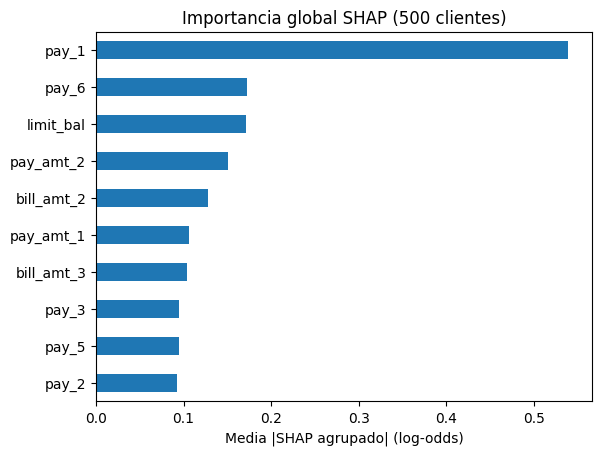

In [ ]:
# Decisión: estimar SHAP global con 500 casos de prueba y fondo independiente de entrenamiento.
# Sin esta separación, las explicaciones no serían comparables con la evaluación fuera de muestra.
import shap
from scipy.special import expit
sample_idx = Xte.sample(500,random_state=SEED).index
background = Xtr.sample(min(500,len(Xtr)),random_state=SEED)
P = model.named_steps['pre']; L = model.named_steps['lr']
explainer = shap.LinearExplainer(L,P.transform(background))
sv = explainer(P.transform(Xte.loc[sample_idx]))
# Identificar la variable de origen de cada columna transformada (sin usar nombres ambiguos).
orig = num.copy()
for c, cats in zip(cat,P.named_transformers_['cat'].categories_): orig += [c]*len(cats)
assert len(orig)==sv.values.shape[1]
def grouped_shap(vals):
    a=pd.DataFrame(vals,columns=orig)
    return a.T.groupby(level=0,sort=False).sum().T
sg=grouped_shap(sv.values)
importance=sg.abs().mean().sort_values(ascending=False)
display(importance.head(5).rename('media_SHAP_abs_logodds').to_frame())
importance.head(10).sort_values().plot.barh(title='Importancia global SHAP (500 clientes)',xlabel='Media |SHAP agrupado| (log-odds)'); plt.show()

FP: real=0, predicho=1, probabilidad=0.6920, base log-odds=-1.7160


,SHAP_logodds,valor_observado
pay_1,1.753975,2
pay_6,0.284574,2
limit_bal,0.215739,40000
pay_amt_2,0.159534,1942
pay_amt_1,0.069828,2000


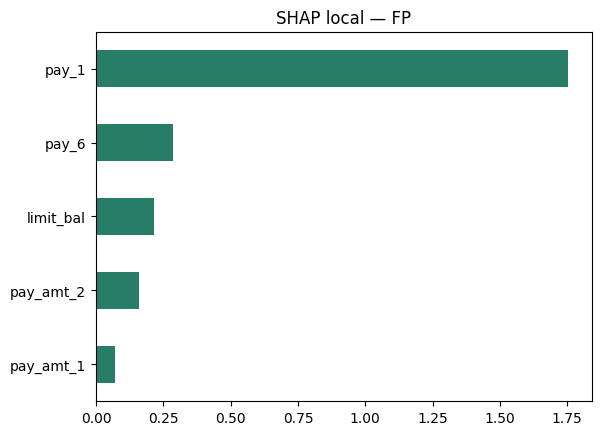

FP: probabilidad 0.692. pay_1 elevó la salida (+1.754 log-odds). pay_4 redujo la salida (-0.046 log-odds). Son contribuciones del modelo, no efectos causales.

FN: real=1, predicho=0, probabilidad=0.3152, base log-odds=-1.7160


,SHAP_logodds,valor_observado
pay_6,0.891795,3
pay_4,-0.639848,5
pay_5,-0.629094,4
pay_1,0.442269,1
limit_bal,0.247630,20000


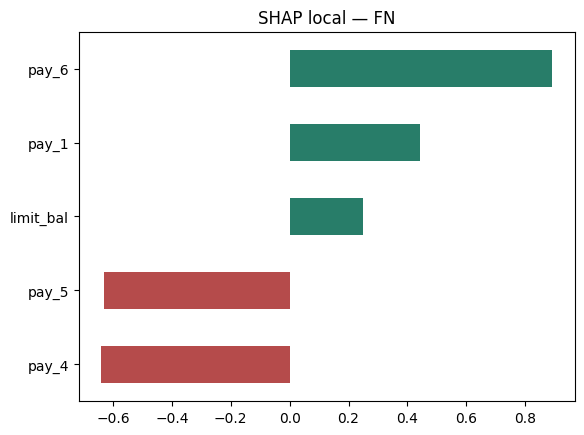

FN: probabilidad 0.315. pay_6 elevó la salida (+0.892 log-odds). pay_4 redujo la salida (-0.640 log-odds). Son contribuciones del modelo, no efectos causales.

In [ ]:
# Decisión: explicar un FP y FN de prueba sin elegir casos convenientes por contribución SHAP.
# Si no aparecen en la muestra, seleccionar el primero de prueba y explicarlo por separado.
local_cases=[]
for tipo,mask in [('FP',(yte==0)&(prob>=.5)),('FN',(yte==1)&(prob<.5))]:
    candidates=prob.index[mask]
    if not len(candidates): print('No existe caso',tipo,'al umbral base'); continue
    in_sample=[i for i in sample_idx if i in set(candidates)]
    i=in_sample[0] if in_sample else candidates[0]
    ev=explainer(P.transform(Xte.loc[[i]])); vals=grouped_shap(ev.values).iloc[0]
    base=float(np.asarray(ev.base_values).ravel()[0]); p=float(expit(base+vals.sum()))
    assert np.isclose(p,prob.loc[i],atol=1e-6)
    top=vals.loc[vals.abs().nlargest(5).index];
    print(f'{tipo}: real={yte.loc[i]}, predicho={int(prob.loc[i]>=.5)}, probabilidad={p:.4f}, base log-odds={base:.4f}')
    display(pd.DataFrame({'SHAP_logodds':top,'valor_observado':Xte.loc[i,top.index]}))
    top.sort_values().plot.barh(title=f'SHAP local — {tipo}',color=['#b54b4b' if x<0 else '#287d69' for x in top.sort_values()]); plt.show()
    pos=vals[vals>0].nlargest(1); neg=vals[vals<0].nsmallest(1)
    msg=f'{tipo}: probabilidad {p:.3f}. '
    if len(pos): msg+=f'{pos.index[0]} elevó la salida ({pos.iloc[0]:+.3f} log-odds). '
    if len(neg): msg+=f'{neg.index[0]} redujo la salida ({neg.iloc[0]:+.3f} log-odds). '
    msg+='Son contribuciones del modelo, no efectos causales.'
    local_cases.append(msg)
    display(Markdown(msg))

In [ ]:
# Decisión: distinguir controles técnicos demostrados de obligaciones organizacionales no evidenciadas.
# Checklist propuesto a partir de semana 13; contrastar con los ocho controles de la guía.
checklist=pd.DataFrame([
('Finalidad definida','Cumple académico','Ficha y contrato; no certifica base jurídica'),
('Propietario y contrato','Parcial','Responsables propuestos, sin designación formal'),
('Calidad de datos','Cumple académico','Conteos de códigos y duplicados; falta validación empresarial'),
('Linaje','Cumple académico','Descarga, hash, semilla y pipeline'),
('Auditoría de equidad','Parcial','Subgrupos y brechas medidos; mitigación pendiente'),
('Transparencia','Cumple académico','SHAP global y local, sin causalidad'),
('Control de acceso','No evidenciado','No hay autorización organizacional ni registros reales'),
('Supervisión humana','No evidenciado','Sin responsable formal ni proceso de revisión')],columns=['control','estado','evidencia'])
display(checklist)
findings=pd.DataFrame([
('H1','Alta' if priority.brecha>=GAP_MAX else 'Media',f'{priority.metrica} por {priority.dimension}: {priority.brecha:.3f}', 'Revisar umbrales, representatividad y proxies; repetir auditoría','Líder del modelo','Antes del piloto','Abierto'),
('H2','Alta','Supervisión humana no evidenciada','Designar revisor y protocolo de revisión y reclamaciones','Dirección de Riesgos','Antes del piloto','Abierto'),
('H3','Alta','Control de acceso y finalidad legal no evidenciados','Definir permisos, finalidad y registros de acceso; revisar marco aplicable','Seguridad y cumplimiento','Antes del piloto','Abierto'),
('H4','Media',f'{int(quality.n_no_definidos.sum())} celdas con códigos no definidos','Validar significado con custodio; versionar diccionario','Custodio de datos','Antes de reentrenar','Abierto')],columns=['id','severidad','evidencia','accion','responsable_propuesto','plazo','estado'])
display(findings)

,control,estado,evidencia
0,Finalidad definida,Cumple académico,Ficha y contrato; no certifica base jurídica
1,Propietario y contrato,Parcial,"Responsables propuestos, sin designación formal"
2,Calidad de datos,Cumple académico,Conteos de códigos y duplicados; falta validac...
3,Linaje,Cumple académico,"Descarga, hash, semilla y pipeline"
4,Auditoría de equidad,Parcial,Subgrupos y brechas medidos; mitigación pendiente
5,Transparencia,Cumple académico,"SHAP global y local, sin causalidad"
6,Control de acceso,No evidenciado,No hay autorización organizacional ni registro...
7,Supervisión humana,No evidenciado,Sin responsable formal ni proceso de revisión


,id,severidad,evidencia,accion,responsable_propuesto,plazo,estado
0,H1,Media,FNR por edad: 0.024,"Revisar umbrales, representatividad y proxies;...",Líder del modelo,Antes del piloto,Abierto
1,H2,Alta,Supervisión humana no evidenciada,Designar revisor y protocolo de revisión y rec...,Dirección de Riesgos,Antes del piloto,Abierto
2,H3,Alta,Control de acceso y finalidad legal no evidenc...,"Definir permisos, finalidad y registros de acc...",Seguridad y cumplimiento,Antes del piloto,Abierto
3,H4,Media,120733 celdas con códigos no definidos,Validar significado con custodio; versionar di...,Custodio de datos,Antes de reentrenar,Abierto


## *Interpretación E3:*

Las variables pay_1, pay_6, limit_bal, pay_amt_2 y bill_amt_2 presentaron las mayores contribuciones SHAP. Estas explican las predicciones, pero no las causas del incumplimiento. De los ocho controles evaluados, cuatro cumplen académicamente, dos parcialmente y dos no están evidenciados. La falta de supervisión humana y control de acceso impide recomendar el despliegue operativo del modelo.

## **Cumplimiento.**

Conforme al enfoque académico de la semana 13, revisar finalidad y protección de datos (Ley 29733), gestión de riesgos, transparencia y supervisión (Ley 31814), y el EU AI Act como referencia internacional. La evaluación de crédito es de alto impacto. Este checklist no es certificación legal; una evaluación real requiere revisión jurídica del mercado y jurisdicción aplicables.

# Ejercicio 4 — Text-to-SQL: construcción y seguridad
El LLM genera propuestas de SQL; no consulta la base directamente ni recibe registros individuales. Se habilita una sola sentencia SELECT/WITH sobre `credito`, se limita la salida a 1 000 filas y se rechaza acceso externo. Para el ejercicio se aceptan únicamente resultados agregados (no se autorizan consultas individuales). Se prueba el mecanismo con casos conocidos y se conservan los estados de ejecución.

In [ ]:
# Decisión: materializar una tabla local y reabrir con permisos mínimos; el prompt solo no protege.
import duckdb, sqlglot, gc
from sqlglot import exp

DB=Path('lc7_credito.duckdb')

# Cerrar conexiones anteriores del kernel que puedan mantener el archivo bloqueado
try:
    con.close()
    del con
except NameError:
    pass

try:
    writer.close()
    del writer
except NameError:
    pass

gc.collect()

if DB.exists():
    try:
        DB.unlink()
    except Exception as e:
        print("Aviso al eliminar archivo:", e)

# La tabla de consultas no necesita id; los atributos demográficos se reservan para auditoría agregada.
sql_df=df.drop(columns=['id'])
writer=duckdb.connect(str(DB)); writer.register('datos',sql_df)
writer.execute('CREATE TABLE credito AS SELECT * FROM datos'); writer.close()

# Forzar la liberación del archivo de base de datos antes de volver a conectarse
del writer
gc.collect()

con=duckdb.connect(str(DB),read_only=True,config={'enable_external_access':'false','threads':2,'memory_limit':'512MB'})
print(con.execute("SELECT COUNT(*) AS n FROM credito").df())
print(con.execute("SELECT current_setting('enable_external_access') AS acceso_externo").df())

       n
0  30000
   acceso_externo
0           False


In [ ]:
# Decisión: analizar el AST SQL, restringir tablas y funciones y exigir consultas agregadas.
# La conexión sigue siendo una capa independiente. Esto es un prototipo, no una frontera de seguridad certificada.
ALLOWED_FUNCTIONS={'COUNT','SUM','AVG','MIN','MAX','ROUND','ABS','COALESCE','NULLIF','CAST','TRY_CAST','CASE','IF','DISTINCT','FLOOR','CEIL','CEILING','PERCENTILE_CONT','QUANTILE_CONT','MEDIAN','STDDEV','STDDEV_POP','STDDEV_SAMP','VARIANCE','VAR_POP','VAR_SAMP','AND','OR','NOT','BETWEEN','IN','GREATEST','LEAST','POWER','POW'}
FORBIDDEN={'Insert','Update','Delete','Drop','Create','Alter','Attach','Detach','Copy','Command','Pragma','Merge','Transaction','Into','LoadData','Export','Import','Use','Set','Grant','Revoke','Execute','Unnest','Lateral','Join','Window','Pivot'}
def clean_sql(raw):
    t=str(raw).strip()
    return re.sub(r'^```(?:sql)?\s*|\s*```$','',t,flags=re.I).strip()
def validate_sql(sql):
    try: stmts=sqlglot.parse(sql,read='duckdb')
    except Exception as e: return False,'Sintaxis no analizable: '+str(e)[:150],None
    if len(stmts)!=1 or not isinstance(stmts[0],exp.Select): return False,'Solo una sentencia SELECT o WITH ... SELECT',None
    tree=stmts[0]
    if any(type(x).__name__ in FORBIDDEN for x in tree.walk()): return False,'Operación no autorizada',None
    if any(isinstance(x,exp.With) and x.args.get('recursive') for x in tree.walk()): return False,'CTE recursiva no permitida',None
    ctes={c.alias_or_name.lower() for c in tree.find_all(exp.CTE)}
    for table in tree.find_all(exp.Table):
        if not isinstance(table.this,exp.Identifier) or table.name.lower() not in {'credito'}|ctes or table.db or table.catalog:
            return False,'Origen no autorizado',None
    if not any(t.name.lower()=='credito' for t in tree.find_all(exp.Table)): return False,'Debe consultar credito',None
    for f in tree.find_all(exp.Func):
        name=f.name.upper() if isinstance(f,exp.Anonymous) else f.sql_name().upper()
        if name not in ALLOWED_FUNCTIONS: return False,'Función no autorizada: '+name,None
    # Restringir a agregación, sin estrellas fuera de COUNT(*) ni agrupación por atributos continuos.
    if not any(isinstance(f,exp.AggFunc) for f in tree.walk()): return False,'Se requieren estadísticas agregadas',None
    if any(not isinstance(s.parent,exp.Count) for s in tree.find_all(exp.Star)): return False,'No se permite exponer filas',None
    # Cada SELECT debe agregar; permitir CTE agregada y SELECT externo sobre resultados agregados.
    for sel in tree.find_all(exp.Select):
        from_=sel.args.get('from_') or sel.args.get('from')
        is_cte=from_ is not None and isinstance(from_.this,exp.Table) and from_.this.name.lower() in ctes
        has_agg=any(isinstance(x,exp.AggFunc) and x.find_ancestor(exp.Select) is sel for x in sel.walk())
        if not has_agg and not is_cte: return False,'No se permiten consultas de detalle',None
        group=sel.args.get('group')
        if group and any(not isinstance(x,exp.Column) or x.name.lower() not in {'education','default','sex','marriage',*paycols} for x in group.expressions):
            return False,'Agrupación no autorizada',None
    return True,'Permitida',tree.sql(dialect='duckdb')
def run_sql(sql):
    ok,reason,normalized=validate_sql(sql)
    if not ok: return {'seguridad':'Bloqueada','ejecucion':False,'detalle':reason,'resultado':None,'sql_normalizado':None}
    try:
        out=con.execute(f'SELECT * FROM ({normalized}) AS resultado LIMIT 1000').df()
        return {'seguridad':'Permitida','ejecucion':True,'detalle':'OK','resultado':out,'sql_normalizado':normalized}
    except Exception as e:
        return {'seguridad':'Permitida','ejecucion':False,'detalle':str(e),'resultado':None,'sql_normalizado':normalized}

In [ ]:
# Decisión: pruebas deterministas de defensa, incluyendo consultas legítimas y ataques simulados locales.
cases=[('SELECT COUNT(*) FROM credito',True),('with t as (select count(*) as n from credito) select n from t',True),
       ('SELECT COUNT(*) FROM credito; DELETE FROM credito',False),('/* comentario */ DROP TABLE credito',False),
       ("SELECT COUNT(*) FROM read_csv('/content/archivo.csv')",False),
       ("SELECT COUNT(*) FROM glob('/content/*')",False),('SELECT * FROM credito',False),
       ('SELECT AVG(limit_bal) FROM credito',True)]
security_tests=[]
for sql,expected_ok in cases:
    r=run_sql(sql); observed=r['ejecucion']; security_tests.append({'consulta':sql,'esperada':expected_ok,'ejecuta':observed,'estado':r['seguridad'],'detalle':r['detalle'],'superada':expected_ok==observed})
security_tests=pd.DataFrame(security_tests); display(security_tests)
# Verificar también el motor sin pasar por el validador (solo base local de práctica).
engine_checks={}
for key,sql in [('escritura','CREATE TABLE prueba_bloqueo(i INTEGER)'),('externo',"SELECT * FROM glob('/content/*')")]:
    try: con.execute(sql); engine_checks[key]=False
    except Exception as e: engine_checks[key]=True; print(key,': bloqueado por motor:',str(e)[:180])
security_ok=bool(security_tests.superada.all() and all(engine_checks.values()))
print('Controles de prueba superados:',security_ok)

,consulta,esperada,ejecuta,estado,detalle,superada
0,SELECT COUNT(*) FROM credito,True,True,Permitida,OK,True
1,with t as (select count(*) as n from credito) ...,True,True,Permitida,OK,True
2,SELECT COUNT(*) FROM credito; DELETE FROM credito,False,False,Bloqueada,Solo una sentencia SELECT o WITH ... SELECT,True
3,/* comentario */ DROP TABLE credito,False,False,Bloqueada,Solo una sentencia SELECT o WITH ... SELECT,True
4,SELECT COUNT(*) FROM read_csv('/content/archiv...,False,False,Bloqueada,Origen no autorizado,True
5,SELECT COUNT(*) FROM glob('/content/*'),False,False,Bloqueada,Origen no autorizado,True
6,SELECT * FROM credito,False,False,Bloqueada,Se requieren estadísticas agregadas,True
7,SELECT AVG(limit_bal) FROM credito,True,True,Permitida,OK,True


escritura : bloqueado por motor: Invalid Input Error: Cannot execute statement of type "CREATE" on database "lc7_credito" which is attached in read-only mode!
externo : bloqueado por motor: Permission Error: Cannot access file "/content/*" - file system operations are disabled by configuration
Controles de prueba superados: True


## *Diccionario y batería de preguntas*
La lista siguiente es una propuesta porque no se proporcionó el documento de guía. Reemplazarla por las preguntas exactas de la guía si difieren, manteniendo ocho respondibles y dos ambiguas. Las consultas de referencia son independientes del LLM.

In [ ]:
# Decisión: aportar semántica al contexto y fijar las referencias antes de pedir respuestas al LLM.
dictionary = """
Tabla credito: una fila por cliente histórico, sin identificador; atributos demográficos únicamente para auditoría agregada.
sex (1 hombre, 2 mujer), age (años), marriage (1 casado, 2 soltero, 3 otro; otros códigos no documentados). Columnas: limit_bal (límite de crédito en NTD), education (código entero 1 posgrado, 2 universidad, 3 secundaria, 4 otros; restantes no documentados), "default" (1 incumple siguiente mes, 0 no incumple).
pay_1 a pay_6: estado de pago de septiembre a abril de 2005, respectivamente; pay_1 corresponde a PAY_0 de origen. -1 pago oportuno, 1 a 9 meses de retraso; -2 y 0 no definidos en el diccionario oficial utilizado; no interpretarlos como mora.
bill_amt_1 a bill_amt_6: importe facturado mensual en NTD; pay_amt_1 a pay_amt_6: importe pagado en NTD. Sufijo 1 septiembre; 6 abril.
No existe información de ganancias, préstamos futuros o causas del incumplimiento. Devuelve solo agregados. No inventes columnas.
"""
questions=[
('P1','¿Cuántos clientes hay en total?', 'SELECT COUNT(*) AS n FROM credito'),
('P2','¿Cuántos clientes incumplieron el siguiente mes?', 'SELECT COUNT(*) AS n FROM credito WHERE "default"=1'),
('P3','¿Qué porcentaje de clientes incumplió?', 'SELECT 100.0*AVG("default") AS porcentaje FROM credito'),
('P4','¿Cuál es el límite de crédito promedio en NTD?', 'SELECT AVG(limit_bal) AS promedio FROM credito'),
('P5','¿Cuál es el límite promedio de los clientes que incumplieron?', 'SELECT AVG(limit_bal) AS promedio FROM credito WHERE "default"=1'),
('P6','¿Cuántos clientes tuvieron al menos un mes de retraso en septiembre?', 'SELECT COUNT(*) AS n FROM credito WHERE pay_1 BETWEEN 1 AND 9'),
('P7','¿Cuál es el porcentaje de incumplimiento por nivel educativo registrado?', 'SELECT education,100.0*AVG("default") AS porcentaje FROM credito GROUP BY education ORDER BY education'),
('P8','¿Cuánto suman los pagos realizados en septiembre?', 'SELECT SUM(pay_amt_1) AS total FROM credito'),
('P9','¿Cuáles son los mejores clientes?', None),
('P10','¿Qué nivel de crédito es adecuado?', None)]
refs={}
for qid,q,sql in questions:
    if sql:
        r=run_sql(sql); assert r['ejecucion'],(qid,r['detalle']); refs[qid]=r['resultado']
        print(qid,q); display(refs[qid])

P1 ¿Cuántos clientes hay en total?


,n
0,30000


P2 ¿Cuántos clientes incumplieron el siguiente mes?


,n
0,6636


P3 ¿Qué porcentaje de clientes incumplió?


,porcentaje
0,22.12


... (6 outputs left out)

P7 ¿Cuál es el porcentaje de incumplimiento por nivel educativo registrado?


,education,porcentaje
0,0,0.000000
1,1,19.234766
2,2,23.734854
3,3,25.157616
4,4,5.691057
5,5,6.428571
6,6,15.686275


P8 ¿Cuánto suman los pagos realizados en septiembre?


,total
0,169907415.0


In [ ]:
# Decisión: conectar un proveedor real mediante secretos; no presentar respuestas simuladas como resultados.
from openai import OpenAI
try:
    from google.colab import userdata
    def secret(k):
        try: return userdata.get(k)
        except Exception: return None
except ImportError:
    import os
    def secret(k): return os.getenv(k)
api_key=secret('LLM_API_KEY'); llm_model=secret('LLM_MODEL'); base_url=secret('LLM_BASE_URL'); provider=secret('LLM_PROVIDER') or ('OpenAI' if not base_url else 'Proveedor compatible con OpenAI')
llm_ready=bool(api_key and llm_model)
client=OpenAI(api_key=api_key,**({'base_url':base_url} if base_url else {}),timeout=45,max_retries=1) if llm_ready else None
print('Proveedor:',provider,'| modelo:',llm_model or 'PENDIENTE','| configuración disponible:',llm_ready)
RULES="""Eres un generador de SQL DuckDB. Responde únicamente una sentencia SELECT o WITH ... SELECT agregada sobre credito; sin acceso externo, modificaciones ni filas individuales. Si una pregunta es ambigua responde únicamente CLARIFY. Si no existe información suficiente responde únicamente NO_SQL. No inventes datos ni nombres de columnas."""
context_before=RULES+'\n'+dictionary
# Mitigación preespecificada: aclarar denominador, unidad, semántica temporal y categorías.
context_after=context_before+"""
REGLAS DE NEGOCIO VERIFICABLES:
- Contar clientes con COUNT(*) porque hay una fila por cliente. Incumplimiento es "default"=1, no el retraso histórico.
- Porcentaje de incumplimiento = 100.0*AVG("default") sobre el universo de la pregunta; no devolver proporción 0–1.
- Retraso de al menos un mes se codifica de 1 a 9, no -2, -1 ni 0.
- No confundir límite de crédito (limit_bal), facturación (bill_amt_i) y pagos (pay_amt_i); montos en NTD.
- Si se pide agrupación por educación, conservar los códigos registrados sin recodificar.
- 'Mejor' o 'adecuado' sin criterio requiere CLARIFY; no elijas una definición por tu cuenta.
"""
def generate_sql(question,context):
    if not llm_ready: raise RuntimeError('Configurar secretos LLM_API_KEY y LLM_MODEL')
    r=client.chat.completions.create(model=llm_model,temperature=0,messages=[{'role':'system','content':context},{'role':'user','content':question}])
    return r.choices[0].message.content or ''
display(Markdown(f"**Interpretación E4 (borrador):** Se superaron {security_tests.superada.sum()} de {len(security_tests)} pruebas del validador. Las dos pruebas independientes del motor se registran arriba. El diccionario permite distinguir retraso de incumplimiento; los permisos mínimos reducen el riesgo de ejecutar SQL inseguro."))

Proveedor: Groq | modelo: openai/gpt-oss-20b | configuración disponible: True


**Interpretación E4 (borrador):** Se superaron 8 de 8 pruebas del validador. Las dos pruebas independientes del motor se registran arriba. El diccionario permite distinguir retraso de incumplimiento; los permisos mínimos reducen el riesgo de ejecutar SQL inseguro.

# Ejercicio 5 — Evaluación del asistente y mitigación
Se comparan resultados de las consultas, no cadenas SQL. Las ocho preguntas respondibles son el denominador de exactitud, alucinación, error semántico y bloqueo. Las dos preguntas ambiguas se informan aparte. Se registran también fallas de proveedor/sintaxis y abstenciones injustificadas; no se ocultan bajo otras categorías. Se conserva la batería idéntica antes y después.

,etapa,id,pregunta,respondible,fecha_utc,respuesta,sql_limpio,seguridad,ejecucion,coincide,tipo,detalle,resultado
0,Antes,P1,¿Cuántos clientes hay en total?,True,2026-11-21T04:16:36.552163+00:00,SELECT COUNT(*) AS total_clients FROM credito;,SELECT COUNT(*) AS total_clients FROM credito;,Permitida,True,True,Acierto,OK,[[30000]]
1,Antes,P2,¿Cuántos clientes incumplieron el siguiente mes?,True,2026-11-21T04:16:36.866224+00:00,SELECT COUNT(*) AS num_defaulting_clients\nFRO...,SELECT COUNT(*) AS num_defaulting_clients\nFRO...,Permitida,True,True,Acierto,OK,[[6636]]
2,Antes,P3,¿Qué porcentaje de clientes incumplió?,True,2026-11-21T04:16:37.335727+00:00,"SELECT 100.0 * SUM(""default"") / COUNT(*) AS de...","SELECT 100.0 * SUM(""default"") / COUNT(*) AS de...",Permitida,True,True,Acierto,OK,[[22.12]]
3,Antes,P4,¿Cuál es el límite de crédito promedio en NTD?,True,2026-11-21T04:16:37.950505+00:00,SELECT AVG(limit_bal) AS avg_limit_bal FROM cr...,SELECT AVG(limit_bal) AS avg_limit_bal FROM cr...,Permitida,True,True,Acierto,OK,[[167484.3226666667]]
4,Antes,P5,¿Cuál es el límite promedio de los clientes qu...,True,2026-11-21T04:16:38.384139+00:00,SELECT AVG(limit_bal) AS avg_limit_bal\nFROM c...,SELECT AVG(limit_bal) AS avg_limit_bal\nFROM c...,Permitida,True,True,Acierto,OK,[[130109.6564195298]]
5,Antes,P6,¿Cuántos clientes tuvieron al menos un mes de ...,True,2026-11-21T04:16:38.862561+00:00,SELECT COUNT(*) AS num_clients_with_delay_sept...,SELECT COUNT(*) AS num_clients_with_delay_sept...,Permitida,True,True,Acierto,OK,[[6818]]
6,Antes,P7,¿Cuál es el porcentaje de incumplimiento por n...,True,2026-11-21T04:16:39.444212+00:00,"SELECT \n education, \n ROUND(AVG(""defau...","SELECT \n education, \n ROUND(AVG(""defau...",Permitida,True,False,Semantica,OK,"[[0,0.0],[1,19.23],[2,23.73],[3,25.16],[4,5.69..."
7,Antes,P8,¿Cuánto suman los pagos realizados en septiembre?,True,2026-11-21T04:16:39.890948+00:00,SELECT SUM(pay_amt_1) AS total_payments_sept F...,SELECT SUM(pay_amt_1) AS total_payments_sept F...,Permitida,True,True,Acierto,OK,[[169907415.0]]
8,Antes,P9,¿Cuáles son los mejores clientes?,False,2026-11-21T04:16:40.208788+00:00,,,Bloqueada,False,False,Bloqueo,Solo una sentencia SELECT o WITH ... SELECT,
9,Antes,P10,¿Qué nivel de crédito es adecuado?,False,2026-11-21T04:16:42.516204+00:00,CLARIFY,CLARIFY,No aplica,False,True,Aclaracion correcta,,


,n,exactitud,alucinacion,semantica,bloqueo,otros,aclaraciones,fallas_proveedor
Antes,8,0.875,0.0,0.125,0.0,0.0,1,0
Despues,8,1.000,0.0,0.000,0.0,0.0,2,0


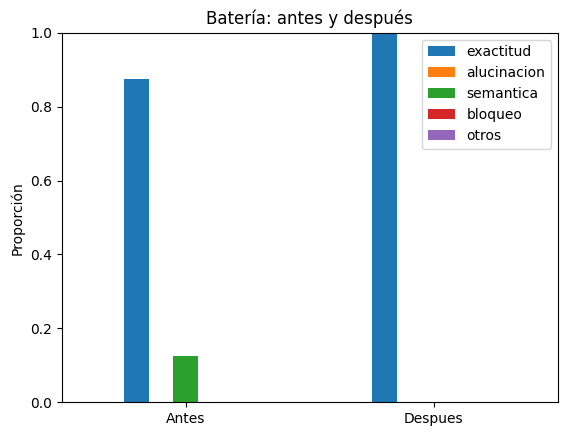

In [ ]:
# Decisión: comparar filas sin exigir alias u orden iguales; tolerancia para números de punto flotante.
def equivalent(a,b):
    if a.shape!=b.shape: return False
    if a.empty: return True
    def row_equal(x,y):
        for u,v in zip(x,y):
            if pd.isna(u) or pd.isna(v):
                if not (pd.isna(u) and pd.isna(v)): return False
            elif isinstance(u,(int,float,np.number)) and isinstance(v,(int,float,np.number)):
                if not np.isclose(u,v,rtol=1e-7,atol=1e-6): return False
            elif str(u)!=str(v): return False
        return True
    pending=list(b.itertuples(index=False,name=None))
    for row in a.itertuples(index=False,name=None):
        match=next((i for i,x in enumerate(pending) if row_equal(row,x)),None)
        if match is None: return False
        pending.pop(match)
    return True

def evaluate(context,stage):
    rows=[]
    for qid,q,ref in questions:
        row=dict(etapa=stage,id=qid,pregunta=q,respondible=ref is not None,fecha_utc=datetime.now(timezone.utc).isoformat(),respuesta='',sql_limpio='',seguridad='No aplica',ejecucion=False,coincide=False,tipo='',detalle='',resultado='')
        try: raw=generate_sql(q,context); row['respuesta']=raw
        except Exception as e:
            # No copiar errores completos de la API que puedan contener datos de configuración.
            row.update(tipo='Proveedor',detalle=type(e).__name__); rows.append(row); continue
        sql=clean_sql(raw); row['sql_limpio']=sql
        if sql.upper() in {'CLARIFY','NO_SQL'}:
            row['tipo']='Aclaracion correcta' if ref is None and sql.upper()=='CLARIFY' else 'Abstencion/Aclaracion incorrecta'
            row['coincide']=row['tipo']=='Aclaracion correcta'; rows.append(row); continue
        r=run_sql(sql); row.update(seguridad=r['seguridad'],ejecucion=r['ejecucion'],detalle=r['detalle'])
        if not r['ejecucion']:
            d=r['detalle'].lower()
            if r['seguridad']=='Bloqueada':
                row['tipo']='Sintaxis' if d.startswith('sintaxis no analizable') else 'Bloqueo'
            elif 'not found' in d or 'does not exist' in d or 'referenced column' in d or 'binder error' in d and 'column' in d:
                row['tipo']='Esquema'
            else: row['tipo']='Sintaxis/Ejecucion'
        else:
            row['resultado']=r['resultado'].to_json(orient='values')
            if ref is None: row['tipo']='Debio aclarar'
            else:
                row['coincide']=equivalent(r['resultado'],refs[qid]); row['tipo']='Acierto' if row['coincide'] else 'Semantica'
        rows.append(row)
    return pd.DataFrame(rows)
def indicators(log):
    ans=log[log.respondible]; counts=ans.tipo.value_counts(); n=len(ans)
    return dict(n=n,exactitud=counts.get('Acierto',0)/n,alucinacion=counts.get('Esquema',0)/n,
                semantica=counts.get('Semantica',0)/n,bloqueo=counts.get('Bloqueo',0)/n,
                otros=(n-sum(counts.get(k,0) for k in ['Acierto','Esquema','Semantica','Bloqueo']))/n,
                aclaraciones=int((log.loc[~log.respondible,'tipo']=='Aclaracion correcta').sum()),
                fallas_proveedor=int((log.tipo=='Proveedor').sum()))
if llm_ready:
    before=evaluate(context_before,'Antes'); after=evaluate(context_after,'Despues')
    comparison=pd.DataFrame([indicators(before),indicators(after)],index=['Antes','Despues'])
    display(pd.concat([before,after],ignore_index=True)); display(comparison)
    comparison[['exactitud','alucinacion','semantica','bloqueo','otros']].plot.bar(rot=0,ylim=(0,1),title='Batería: antes y después'); plt.ylabel('Proporción'); plt.show()
else:
    before=after=comparison=None
    print('PENDIENTE: configurar proveedor y ejecutar ambas baterías. No se calculan métricas sin respuestas reales.')

## *Interpretación E5:*
 La exactitud se mantuvo en 87,5 %, sin alucinaciones de esquema ni bloqueos. El error semántico pasó de 12,5 % a 0 %; sin embargo, se registró una falla del proveedor (12,5 %) en la misma pregunta. Por ello, no se demuestra que la mitigación haya sido efectiva. Se recomienda repetir la evaluación y ampliar la batería de preguntas.

# Ejercicio 6 — Decisión integrada y sensibilidad

Se aplican las reglas propuestas fijadas al inicio, no ajustadas según los resultados. Para el modelo: no usar todavía si falta evidencia organizacional esencial, ROC-AUC insuficiente, brecha de error >0,20 o recall/FPR fuera de límites; usar con condiciones si supera los mínimos pero presenta brecha >0,10; usar (con monitoreo) si cumple todos los controles. Para el asistente: no usar todavía si falla seguridad, hay fallas del proveedor, exactitud <75 % o no aclara las dos preguntas; usar con condiciones si supera mínimos pero no cumple 100 % de aciertos y cero fallas. Incluso con 100 %, el piloto sigue condicionado por el tamaño de la batería y ausencia de evidencia operativa. Son reglas académicas, no criterios de aprobación legal.

,umbral,ROC_AUC,n,positivos_reales,negativos_reales,VN,FP,FN,VP,tasa_base,positivos_pred,exactitud,recall,precision,FPR,FNR,brecha_error_max,decision,condicion,decision_si_gobierno_validado
0,0.3,0.7838,9000,1991,7009,6352,657,1016,975,0.2212,0.1813,0.8141,0.4897,0.5974,0.0937,0.5103,0.0539,No usar todavía,Gobierno esencial no evidenciado,Usar con monitoreo
1,0.5,0.7838,9000,1991,7009,6680,329,1266,725,0.2212,0.1171,0.8228,0.3641,0.6879,0.0469,0.6359,0.0236,No usar todavía,Gobierno esencial no evidenciado,No usar todavía
2,0.7,0.7838,9000,1991,7009,6900,109,1628,363,0.2212,0.0524,0.8070,0.1823,0.7691,0.0156,0.8177,0.0233,No usar todavía,Gobierno esencial no evidenciado,No usar todavía


,dimension,grupo,n,positivos_reales,negativos_reales,VN,FP,FN,VP,tasa_base,positivos_pred,exactitud,recall,precision,FPR,FNR,elegible_n,elegible_FNR,elegible_FPR,umbral
0,sexo,Hombre,3557,815,2742,2450,292,401,414,0.2291,0.1985,0.8052,0.5080,0.5864,0.1065,0.4920,True,True,True,0.3
1,sexo,Mujer,5443,1176,4267,3902,365,615,561,0.2161,0.1701,0.8200,0.4770,0.6058,0.0855,0.5230,True,True,True,0.3
2,edad,≤29,2831,665,2166,1944,222,327,338,0.2349,0.1978,0.8061,0.5083,0.6036,0.1025,0.4917,True,True,True,0.3
3,edad,30–39,3414,674,2740,2495,245,336,338,0.1974,0.1708,0.8298,0.5015,0.5798,0.0894,0.4985,True,True,True,0.3
4,edad,40–49,1948,460,1488,1357,131,251,209,0.2361,0.1745,0.8039,0.4543,0.6147,0.0880,0.5457,True,True,True,0.3
5,edad,≥50,807,192,615,556,59,102,90,0.2379,0.1846,0.8005,0.4688,0.6040,0.0959,0.5312,True,True,True,0.3
6,estado_civil,Casado,4150,985,3165,2878,287,499,486,0.2373,0.1863,0.8106,0.4934,0.6287,0.0907,0.5066,True,True,True,0.3
7,estado_civil,No definido,16,2,14,12,2,1,1,0.1250,0.1875,0.8125,0.5000,0.3333,0.1429,0.5000,False,False,False,0.3
8,estado_civil,Otro,89,25,64,58,6,13,12,0.2809,0.2022,0.7865,0.4800,0.6667,0.0938,0.5200,False,False,False,0.3
9,estado_civil,Soltero,4745,979,3766,3404,362,503,476,0.2063,0.1766,0.8177,0.4862,0.5680,0.0961,0.5138,True,True,True,0.3


,dimension,metrica,grupo_mayor,grupo_menor,n_mayor,n_menor,tasa_mayor,tasa_menor,brecha,razon,umbral
0,edad,recall,≤29,40–49,2831,1948,0.5083,0.4543,0.0539,0.8939,0.3
1,edad,FNR,40–49,≤29,1948,2831,0.5457,0.4917,0.0539,0.9012,0.3
2,sexo,FNR,Mujer,Hombre,5443,3557,0.5230,0.4920,0.0309,0.9408,0.3
3,sexo,recall,Hombre,Mujer,3557,5443,0.5080,0.4770,0.0309,0.9391,0.3
4,sexo,positivos_pred,Hombre,Mujer,3557,5443,0.1985,0.1701,0.0284,0.8571,0.3
5,edad,positivos_pred,≤29,30–39,2831,3414,0.1978,0.1708,0.0270,0.8633,0.3
6,sexo,FPR,Hombre,Mujer,3557,5443,0.1065,0.0855,0.0210,0.8033,0.3
7,edad,FPR,≤29,40–49,2831,1948,0.1025,0.0880,0.0145,0.8590,0.3
8,estado_civil,positivos_pred,Casado,Soltero,4150,4745,0.1863,0.1766,0.0097,0.9481,0.3
9,estado_civil,FNR,Soltero,Casado,4745,4150,0.5138,0.5066,0.0072,0.9860,0.3


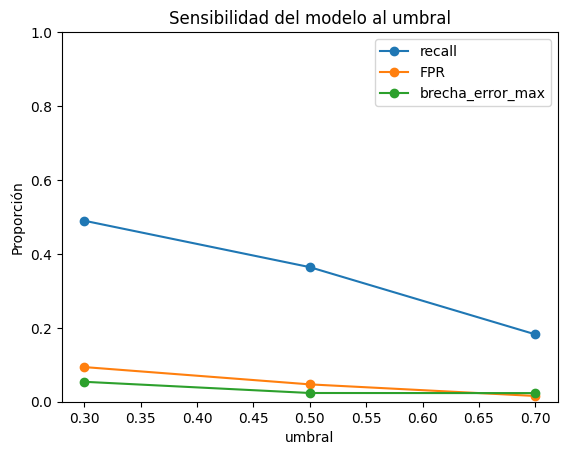

,etapa,decision,motivo
0,Antes,Usar con condiciones,Revisión humana del SQL y resultados; ampliar ...
1,Despues,No usar todavía,"No supera mínimos de seguridad, exactitud o ac..."


Modelo: No usar todavía | Gobierno esencial no evidenciado 
Asistente: No usar todavía | No supera mínimos de seguridad, exactitud o aclaración


In [ ]:
# Decisión: conservar el modelo fijo y cambiar solo el umbral; permite identificar el costo de cada política.
def model_decision(m,g,org=True):
    errors=g[g.metrica.isin(['FNR','FPR'])]
    if errors.empty: return 'No usar todavía','Auditoría de brechas insuficiente'
    gap=errors.brecha.max()
    if org and not all(ORG.values()): return 'No usar todavía','Gobierno esencial no evidenciado'
    if auc<MODEL_AUC_MIN or m['recall']<MODEL_RECALL_MIN or m['FPR']>MODEL_FPR_MAX or gap>GAP_HARD:
        return 'No usar todavía','Métrica o brecha fuera del límite'
    if gap>GAP_MAX: return 'Usar con condiciones','Mitigar brecha y reauditar'
    return 'Usar con monitoreo','Cumple criterios técnicos propuestos'
rows=[]; all_groups=[]; all_gaps=[]
for t in THRESHOLDS:
    m=metrics(yte,prob>=t); g=audit_groups(t); gaps=gap_table(g)
    all_groups.append(g.assign(umbral=t)); all_gaps.append(gaps.assign(umbral=t))
    err_gap=gaps.loc[gaps.metrica.isin(['FNR','FPR']),'brecha'].max()
    rows.append({'umbral':t,'ROC_AUC':auc,**m,'brecha_error_max':err_gap,'decision':model_decision(m,gaps)[0],
                 'condicion':model_decision(m,gaps)[1],'decision_si_gobierno_validado':model_decision(m,gaps,org=False)[0]})
sensitivity=pd.DataFrame(rows); display(sensitivity.round(4)); display(pd.concat(all_groups).round(4)); display(pd.concat(all_gaps).round(4))
sensitivity.set_index('umbral')[['recall','FPR','brecha_error_max']].plot(marker='o',ylim=(0,1),title='Sensibilidad del modelo al umbral'); plt.ylabel('Proporción'); plt.show()
def sql_decision(m):
    if m is None: return 'No usar todavía','Sin evaluación real del proveedor'
    if not security_ok or m['fallas_proveedor'] or m['exactitud']<SQL_COND or m['aclaraciones']<2:
        return 'No usar todavía','No supera mínimos de seguridad, exactitud o aclaración'
    if m['exactitud']>=SQL_USE and m['alucinacion']==0 and m['semantica']==0 and m['bloqueo']==0:
        return 'Usar con condiciones','Batería pequeña; ampliar evidencia y validar acceso'
    return 'Usar con condiciones','Revisión humana del SQL y resultados; ampliar batería'
model_final,model_reason=model_decision(global50,gaps50)
if comparison is not None:
    sql_before=sql_decision(comparison.loc['Antes']); sql_final,sql_reason=sql_decision(comparison.loc['Despues'])
    display(pd.DataFrame([{'etapa':'Antes','decision':sql_before[0],'motivo':sql_before[1]}, {'etapa':'Despues','decision':sql_final,'motivo':sql_reason}]))
else: sql_final,sql_reason=sql_decision(None)
print('Modelo:',model_final,'|',model_reason,'\nAsistente:',sql_final,'|',sql_reason)

### 6.1. Curvas de aprendizaje del modelo

Las curvas de aprendizaje permiten analizar el desempeño del modelo a medida que aumenta el volumen de datos de entrenamiento. Se utiliza ROC-AUC como métrica de evaluación y una validación cruzada estratificada de cinco particiones para identificar posibles problemas de sobreajuste, subajuste y capacidad de generalización. El conjunto de prueba permanece independiente de este análisis.

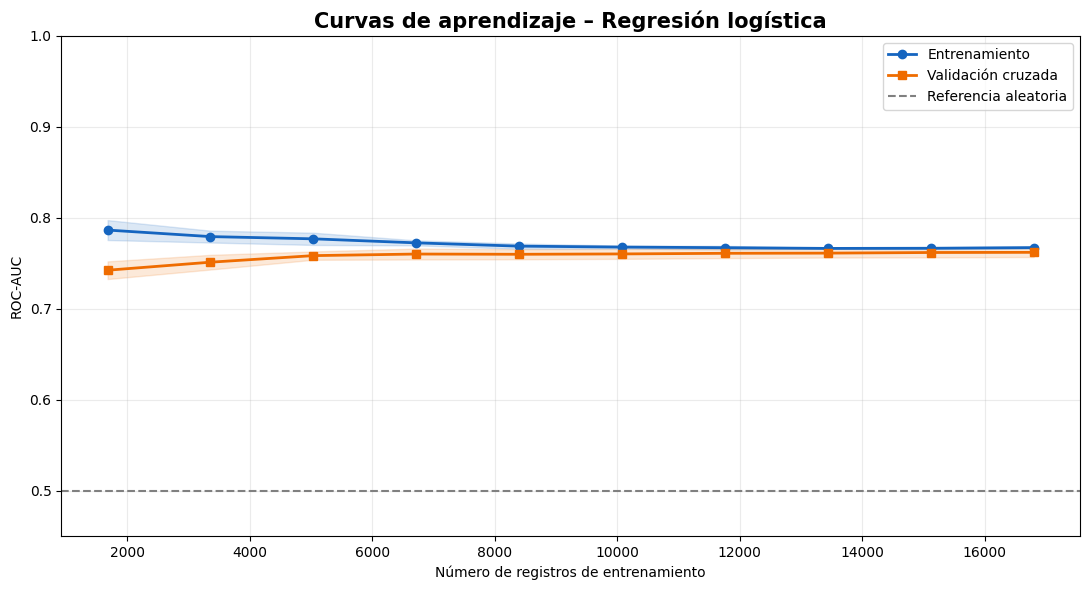

,Registros,AUC_entrenamiento,AUC_validacion,Desv_entrenamiento,Desv_validacion,Brecha
0,1680,0.7865,0.7424,0.0109,0.0097,0.0441
1,3360,0.7793,0.7512,0.0065,0.0081,0.0281
2,5040,0.7769,0.7584,0.0067,0.0046,0.0185
3,6720,0.7724,0.7602,0.0028,0.0060,0.0123
4,8400,0.7688,0.7599,0.0029,0.0055,0.0089
5,10080,0.7678,0.7603,0.0016,0.0054,0.0075
6,11760,0.7671,0.7610,0.0020,0.0053,0.0062
7,13440,0.7663,0.7612,0.0005,0.0049,0.0052
8,15120,0.7665,0.7618,0.0010,0.0054,0.0047
9,16800,0.7672,0.7620,0.0012,0.0051,0.0052


AUC final entrenamiento: 0.7672
AUC final validación: 0.7620
Brecha final: 0.0052


In [ ]:

from sklearn.model_selection import learning_curve, StratifiedKFold
from sklearn.base import clone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Validación cruzada estratificada para conservar
# la proporción de clientes que incumplen.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

# Evaluar el mismo pipeline con diferentes tamaños
# de entrenamiento, sin utilizar el conjunto de prueba.
sizes, train_scores, val_scores = learning_curve(
    estimator=clone(model),
    X=Xtr,
    y=ytr,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv,
    scoring="roc_auc",
    shuffle=True,
    random_state=SEED,
    n_jobs=2
)

# Calcular medias y desviaciones estándar.
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

# Generar gráfico.
plt.figure(figsize=(11, 6))

plt.plot(
    sizes, train_mean, "o-",
    color="#1565C0",
    label="Entrenamiento",
    linewidth=2
)

plt.plot(
    sizes, val_mean, "s-",
    color="#EF6C00",
    label="Validación cruzada",
    linewidth=2
)

plt.fill_between(
    sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.15,
    color="#1565C0"
)

plt.fill_between(
    sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.15,
    color="#EF6C00"
)

plt.axhline(
    y=0.5, color="gray",
    linestyle="--",
    label="Referencia aleatoria"
)

plt.title(
    "Curvas de aprendizaje – Regresión logística",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Número de registros de entrenamiento")
plt.ylabel("ROC-AUC")
plt.ylim(0.45, 1.0)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Tabla de resultados.
learning_results = pd.DataFrame({
    "Registros": sizes,
    "AUC_entrenamiento": train_mean,
    "AUC_validacion": val_mean,
    "Desv_entrenamiento": train_std,
    "Desv_validacion": val_std,
    "Brecha": train_mean - val_mean
})

display(learning_results.round(4))

print(f"AUC final entrenamiento: {train_mean[-1]:.4f}")
print(f"AUC final validación: {val_mean[-1]:.4f}")
print(f"Brecha final: {train_mean[-1]-val_mean[-1]:.4f}")


### 6.2. Curvas ROC y capacidad de generalización

Se comparan las curvas ROC del conjunto de entrenamiento y de prueba para evaluar la capacidad del modelo de distinguir entre clientes que incumplen y aquellos que no incumplen. Asimismo, se identifican los puntos de operación correspondientes a los umbrales de 0,30; 0,50 y 0,70, con la finalidad de analizar el equilibrio entre la detección de incumplimientos y las falsas alertas.

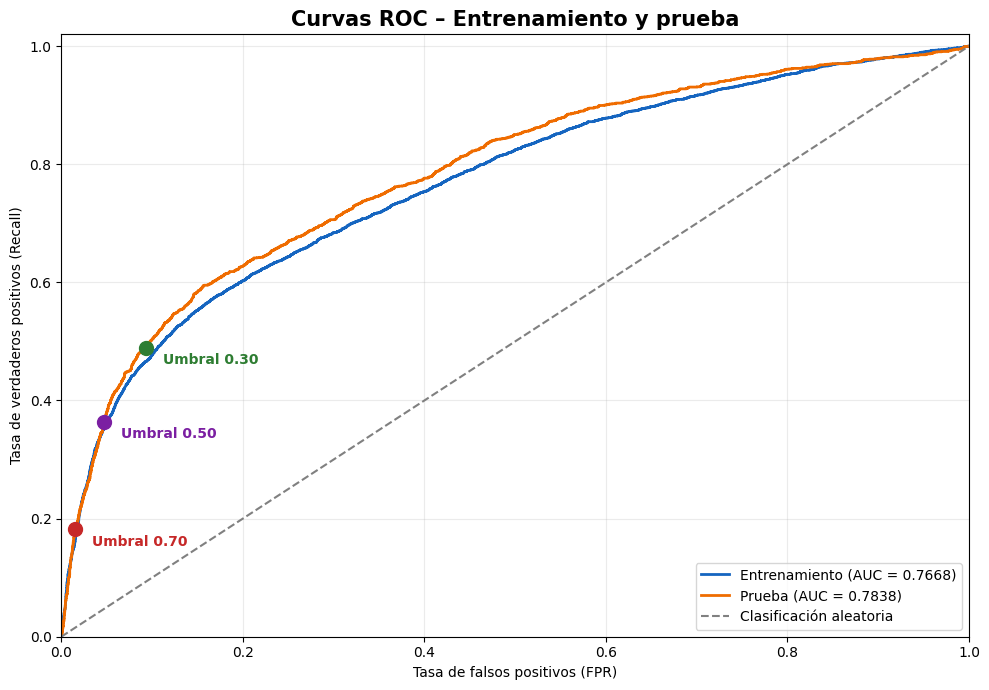

ROC-AUC entrenamiento: 0.7668
ROC-AUC prueba: 0.7838
Diferencia de AUC: -0.0169


In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score

# Obtener probabilidades del modelo ya entrenado.
prob_train = model.predict_proba(Xtr)[:, 1]
prob_test = model.predict_proba(Xte)[:, 1]

# Calcular las curvas ROC.
fpr_train, tpr_train, _ = roc_curve(ytr, prob_train)
fpr_test, tpr_test, _ = roc_curve(yte, prob_test)

auc_train = roc_auc_score(ytr, prob_train)
auc_test = roc_auc_score(yte, prob_test)

fig, ax = plt.subplots(figsize=(10, 7))

ax.plot(
    fpr_train, tpr_train,
    color="#1565C0",
    linewidth=2,
    label=f"Entrenamiento (AUC = {auc_train:.4f})"
)

ax.plot(
    fpr_test, tpr_test,
    color="#EF6C00",
    linewidth=2,
    label=f"Prueba (AUC = {auc_test:.4f})"
)

# Referencia de clasificación aleatoria.
ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Clasificación aleatoria"
)

# Identificar los tres umbrales del ejercicio 6.
colors = ["#2E7D32", "#7B1FA2", "#C62828"]

for t, color in zip([0.30, 0.50, 0.70], colors):

    m = metrics(yte, prob_test >= t)

    ax.scatter(
        m["FPR"], m["recall"],
        s=100,
        color=color,
        zorder=5
    )

    ax.annotate(
        f"Umbral {t:.2f}",
        (m["FPR"], m["recall"]),
        xytext=(12, -12),
        textcoords="offset points",
        color=color,
        fontweight="bold"
    )

ax.set_title(
    "Curvas ROC – Entrenamiento y prueba",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

print(f"ROC-AUC entrenamiento: {auc_train:.4f}")
print(f"ROC-AUC prueba: {auc_test:.4f}")
print(f"Diferencia de AUC: {auc_train-auc_test:.4f}")


### 6.3. Curvas ROC por subgrupos
Para fortalecer el componente de auditoría de equidad, también agregaría una comparación de las curvas ROC por sexo, edad y estado civil.

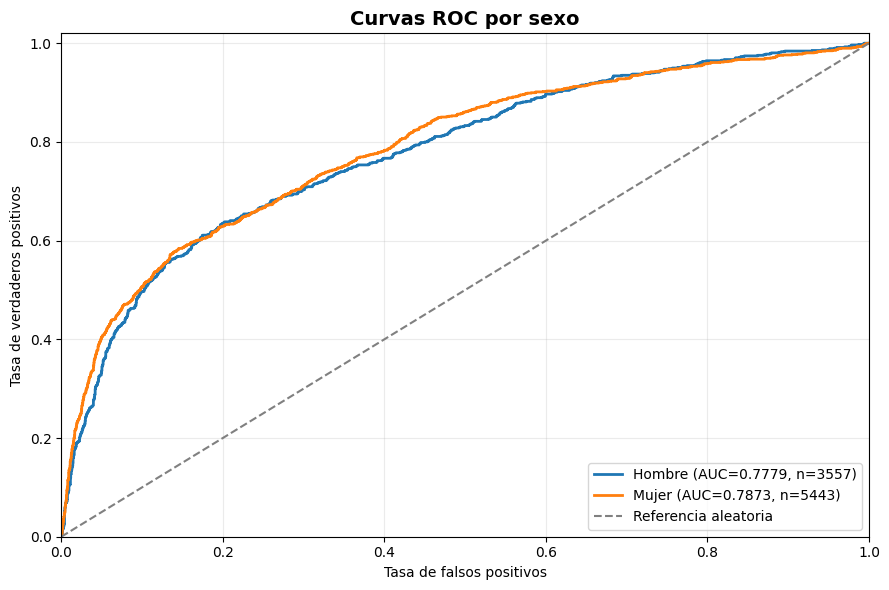

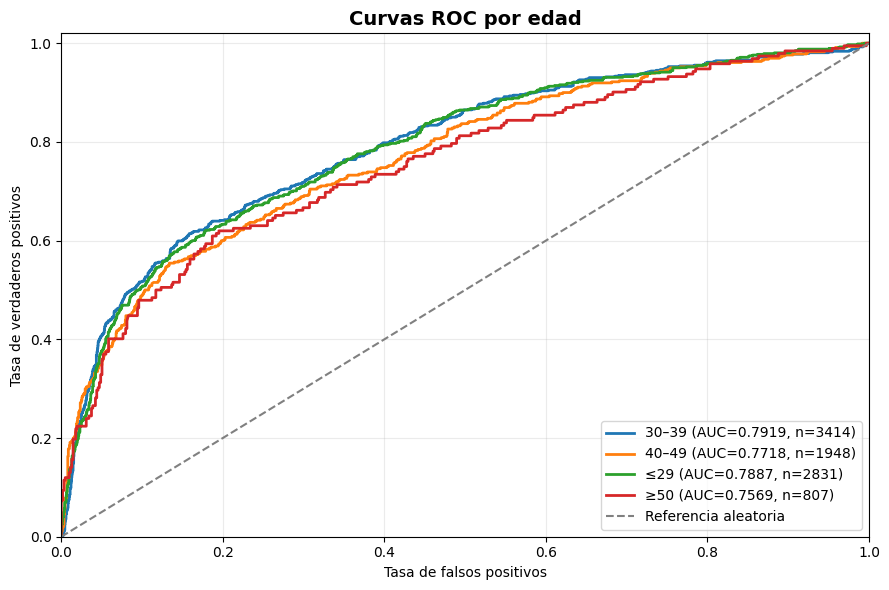

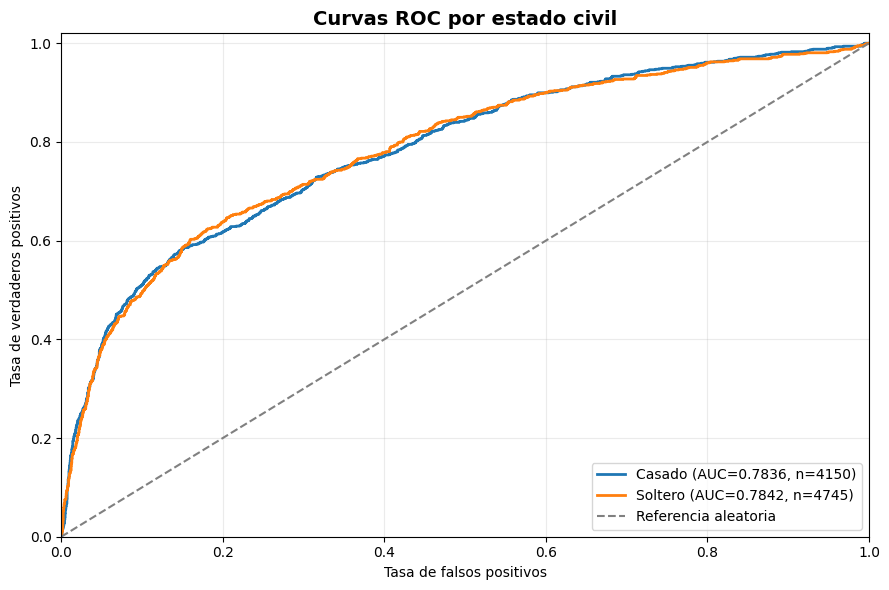

,Dimension,Grupo,n,ROC_AUC
0,Sexo,Hombre,3557,0.7779
1,Sexo,Mujer,5443,0.7873
2,Edad,30–39,3414,0.7919
3,Edad,40–49,1948,0.7718
4,Edad,≤29,2831,0.7887
5,Edad,≥50,807,0.7569
6,Estado civil,Casado,4150,0.7836
7,Estado civil,Soltero,4745,0.7842


In [ ]:

# Comparar la capacidad de discriminación por subgrupo.
# Las variables demográficas se usan solo en auditoría.

audit_roc = pd.DataFrame({
    "real": np.asarray(yte),
    "probabilidad": np.asarray(prob_test),
    "Sexo": df.loc[test_idx, "sex"].map({
        1: "Hombre", 2: "Mujer"
    }).to_numpy(),
    "Edad": pd.cut(
        df.loc[test_idx, "age"],
        bins=[0, 29, 39, 49, np.inf],
        labels=["≤29", "30–39", "40–49", "≥50"]
    ).to_numpy(),
    "Estado civil": df.loc[test_idx, "marriage"].map({
        0: "No definido",
        1: "Casado",
        2: "Soltero",
        3: "Otro"
    }).to_numpy()
})

roc_groups = []

for dimension in ["Sexo", "Edad", "Estado civil"]:

    plt.figure(figsize=(9, 6))

    for grupo, datos in audit_roc.groupby(
        dimension, observed=True
    ):

        # Evitar estimaciones inestables en grupos pequeños.
        if len(datos) < 100:
            continue

        if datos["real"].value_counts().reindex(
            [0, 1], fill_value=0
        ).min() < 20:
            continue

        fpr_g, tpr_g, _ = roc_curve(
            datos["real"],
            datos["probabilidad"]
        )

        auc_g = roc_auc_score(
            datos["real"],
            datos["probabilidad"]
        )

        plt.plot(
            fpr_g, tpr_g,
            linewidth=2,
            label=f"{grupo} (AUC={auc_g:.4f}, n={len(datos)})"
        )

        roc_groups.append({
            "Dimension": dimension,
            "Grupo": grupo,
            "n": len(datos),
            "ROC_AUC": auc_g
        })

    plt.plot(
        [0, 1], [0, 1],
        "--", color="gray",
        label="Referencia aleatoria"
    )

    plt.title(
        f"Curvas ROC por {dimension.lower()}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.xlim(0, 1)
    plt.ylim(0, 1.02)
    plt.grid(alpha=0.25)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

display(pd.DataFrame(roc_groups).round(4))


## 6.5. Análisis de Odds Ratio de la regresión logística

Se analizan los coeficientes del modelo mediante Odds Ratio (OR), calculados a partir de la función exponencial de los coeficientes de la regresión logística. El propósito es identificar las variables asociadas con mayores o menores momios estimados de incumplimiento crediticio, manteniendo constantes las demás variables.

Para las variables numéricas estandarizadas se evalúa el incremento de una desviación estándar. Para las variables categóricas se establecen categorías de referencia explícitas. Los resultados representan asociaciones aprendidas por el modelo y no relaciones causales.

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Recuperar los componentes del pipeline entrenado.
preprocesador = model.named_steps["pre"]
regresion = model.named_steps["lr"]

coef = regresion.coef_[0]
encoder = preprocesador.named_transformers_["cat"]

resultados_or = []

# Variables numéricas:
# efecto de aumentar una desviación estándar.
for variable, beta in zip(num, coef[:len(num)]):

    resultados_or.append({
        "Variable": variable,
        "Comparacion": "+1 desviación estándar",
        "Beta": beta
    })

# Variables categóricas:
# comparar cada categoría con una referencia explícita.
referencias = {
    "education": 2,
    **{v: -1 for v in paycols}
}

posicion = len(num)

for variable, categorias in zip(cat, encoder.categories_):

    betas = coef[posicion:posicion + len(categorias)]

    referencia = referencias[variable]

    if referencia not in categorias:
        referencia = categorias[0]

    idx_ref = np.where(categorias == referencia)[0][0]
    beta_ref = betas[idx_ref]

    for categoria, beta in zip(categorias, betas):

        if categoria == referencia:
            continue

        resultados_or.append({
            "Variable": variable,
            "Comparacion": f"{categoria} frente a {referencia}",
            "Beta": beta - beta_ref
        })

    posicion += len(categorias)

# Transformar los coeficientes en Odds Ratio.
odds_ratio = pd.DataFrame(resultados_or)

odds_ratio["OR"] = np.exp(odds_ratio["Beta"])

odds_ratio["Cambio_odds_pct"] = (
    odds_ratio["OR"] - 1
) * 100

odds_ratio["Magnitud"] = odds_ratio["Beta"].abs()

odds_ratio["Efecto"] = np.select(
    [
        odds_ratio["OR"] > 1,
        odds_ratio["OR"] < 1
    ],
    [
        "Aumenta los momios",
        "Reduce los momios"
    ],
    default="Sin variación"
)

odds_ratio = odds_ratio.sort_values(
    "Magnitud",
    ascending=False
).reset_index(drop=True)

display(odds_ratio.round(4))


,Variable,Comparacion,Beta,OR,Cambio_odds_pct,Magnitud,Efecto
0,pay_1,3 frente a -1,1.5123,4.5373,353.7295,1.5123,Aumenta los momios
1,pay_1,2 frente a -1,1.4815,4.3997,339.9737,1.4815,Aumenta los momios
2,education,4 frente a 2,-1.2344,0.2910,-70.9003,1.2344,Reduce los momios
3,pay_1,4 frente a -1,1.2179,3.3802,238.0151,1.2179,Aumenta los momios
4,education,6 frente a 2,-1.0825,0.3387,-66.1251,1.0825,Reduce los momios
...,...,...,...,...,...,...,...
71,pay_4,6 frente a -1,-0.0133,0.9868,-1.3193,0.0133,Reduce los momios
72,pay_3,0 frente a -1,0.0116,1.0117,1.1696,0.0116,Aumenta los momios
73,pay_5,-2 frente a -1,-0.0104,0.9897,-1.0314,0.0104,Reduce los momios
74,pay_amt_4,+1 desviación estándar,0.0084,1.0085,0.8457,0.0084,Aumenta los momios


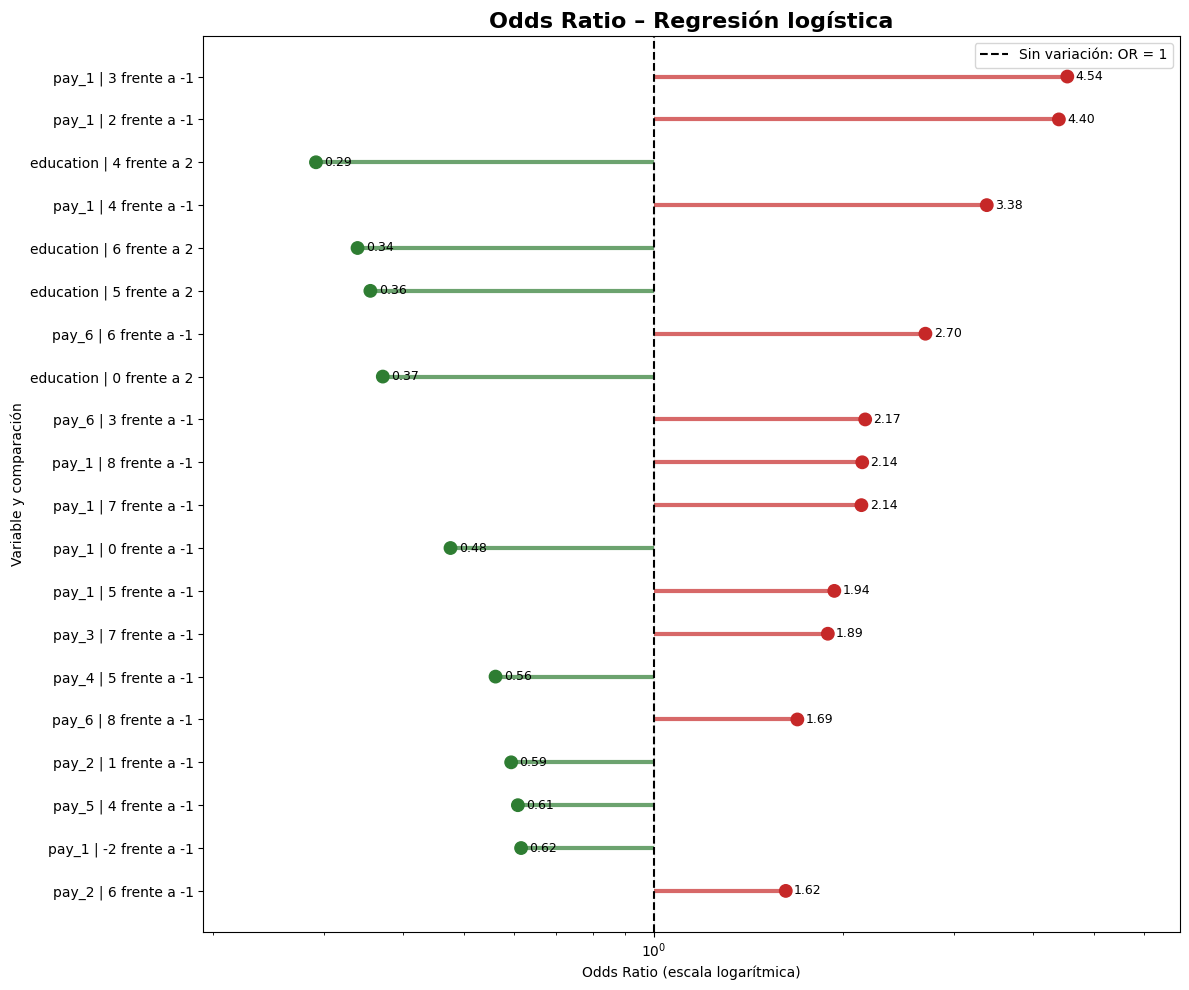

In [ ]:

top_or = odds_ratio.head(20).copy()

top_or["Etiqueta"] = (
    top_or["Variable"] + " | " +
    top_or["Comparacion"]
)

top_or = top_or.iloc[::-1]

colores = np.where(
    top_or["OR"] > 1,
    "#C62828",
    "#2E7D32"
)

fig, ax = plt.subplots(figsize=(12, 10))

ax.hlines(
    y=top_or["Etiqueta"],
    xmin=np.minimum(1, top_or["OR"]),
    xmax=np.maximum(1, top_or["OR"]),
    color=colores,
    linewidth=3,
    alpha=0.7
)

ax.scatter(
    top_or["OR"],
    top_or["Etiqueta"],
    c=colores,
    s=80,
    zorder=3
)

ax.axvline(
    1,
    color="black",
    linestyle="--",
    label="Sin variación: OR = 1"
)

for i, valor in enumerate(top_or["OR"]):
    ax.annotate(
        f"{valor:.2f}",
        (valor, i),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xscale("log")
ax.margins(x=0.15)

ax.set_title(
    "Odds Ratio – Regresión logística",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Odds Ratio (escala logarítmica)")
ax.set_ylabel("Variable y comparación")
ax.grid(axis="x", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()


### 6.6. Importancia predictiva mediante permutación

Se evalúa la importancia de cada variable mediante la permutación aleatoria de sus valores en el conjunto de prueba. La disminución del ROC-AUC permite estimar cuánto depende el desempeño predictivo del modelo de cada variable. Se realizan diez repeticiones para obtener una estimación media y su variabilidad. Este análisis es descriptivo y no se utiliza para modificar el modelo evaluado.

,Variable,Disminucion_AUC,Desviacion,AUC_permutado
0,pay_1,0.1363,0.0051,0.6474
1,limit_bal,0.0217,0.0019,0.7621
2,pay_6,0.0148,0.0020,0.7690
3,bill_amt_2,0.0100,0.0010,0.7738
4,pay_3,0.0090,0.0012,0.7747
5,pay_4,0.0077,0.0017,0.7761
6,pay_amt_1,0.0076,0.0014,0.7762
7,bill_amt_3,0.0076,0.0010,0.7762
8,pay_5,0.0070,0.0009,0.7767
9,bill_amt_5,0.0063,0.0009,0.7775


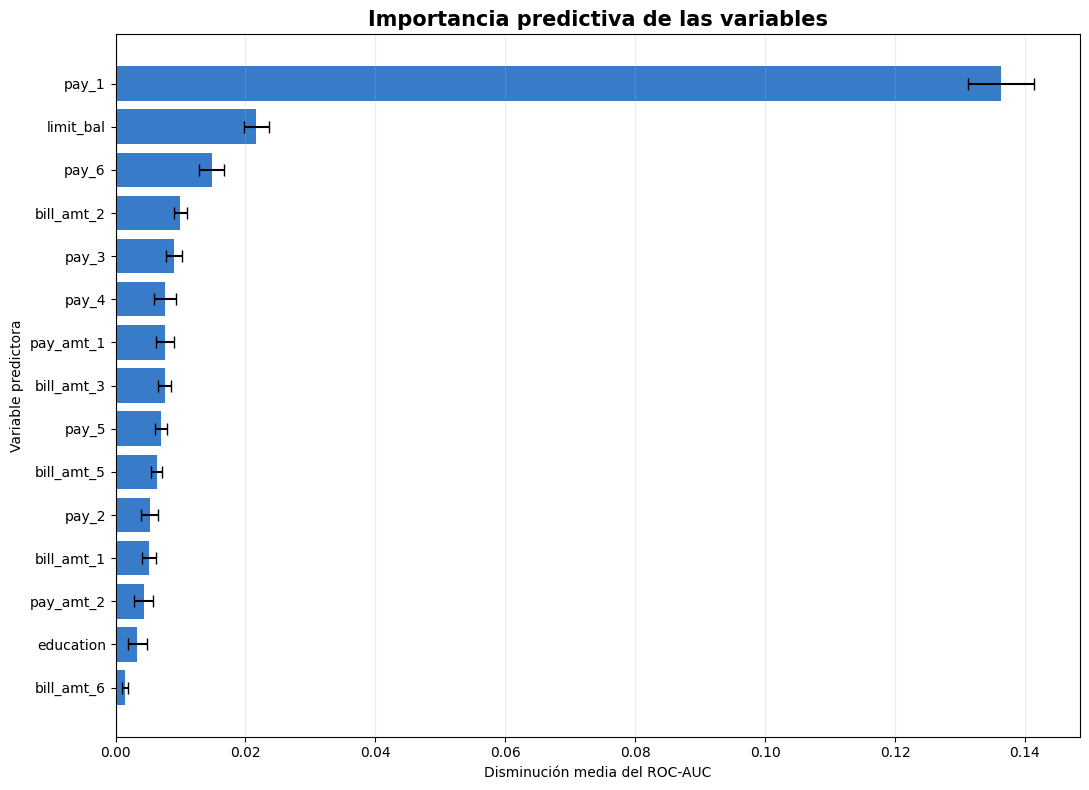

ROC-AUC original: 0.7838

Cinco variables con mayor aporte predictivo:


,Variable,Disminucion_AUC,Desviacion,AUC_permutado
0,pay_1,0.1363,0.0051,0.6474
1,limit_bal,0.0217,0.0019,0.7621
2,pay_6,0.0148,0.0020,0.7690
3,bill_amt_2,0.0100,0.0010,0.7738
4,pay_3,0.0090,0.0012,0.7747


In [ ]:

from sklearn.inspection import permutation_importance

# Evaluar variables originales, antes de la codificación.
# No se modifican los parámetros del modelo entrenado.

perm = permutation_importance(
    estimator=model,
    X=Xte,
    y=yte,
    scoring="roc_auc",
    n_repeats=10,
    random_state=SEED,
    n_jobs=2
)

importancia = pd.DataFrame({
    "Variable": Xte.columns,
    "Disminucion_AUC": perm.importances_mean,
    "Desviacion": perm.importances_std
})

importancia = importancia.sort_values(
    "Disminucion_AUC",
    ascending=False
).reset_index(drop=True)

auc_base = roc_auc_score(
    yte, model.predict_proba(Xte)[:, 1]
)

importancia["AUC_permutado"] = (
    auc_base - importancia["Disminucion_AUC"]
)

display(importancia.round(4))

# Gráfico de importancia predictiva.
top = importancia.head(15).iloc[::-1]

plt.figure(figsize=(11, 8))

plt.barh(
    top["Variable"],
    top["Disminucion_AUC"],
    xerr=top["Desviacion"],
    color="#1565C0",
    alpha=0.85,
    capsize=4
)

plt.axvline(0, color="gray", linestyle="--")

plt.title(
    "Importancia predictiva de las variables",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disminución media del ROC-AUC")
plt.ylabel("Variable predictora")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

print("ROC-AUC original:", round(auc_base, 4))

print("\nCinco variables con mayor aporte predictivo:")
display(importancia.head(5).round(4))


## *Interpretación E6 :*

 El modelo obtuvo un ROC-AUC de 0,7838. El umbral de 0,30 alcanzó el mayor recall (48,97 %), aunque presentó una brecha máxima de 5,39 puntos porcentuales. El asistente mantuvo una exactitud de 87,5 %, pero registró una falla del proveedor. Según las reglas establecidas, ninguna herramienta debe utilizarse todavía hasta resolver los controles pendientes..

# Cierre — Preguntas A, B y C (propuestas; cotejar con guía)

Las respuestas siguientes se generan con los resultados del propio notebook.

## *A. ¿Qué evidencia sustenta la decisión del modelo?*

El modelo obtuvo un ROC-AUC de 0,7838, un recall de 36,41 % y una tasa de falsos negativos de 63,59 % con el umbral de 0,50. La mayor brecha de error fue de 2,36 puntos porcentuales por edad. Se recomienda no usar todavía el modelo debido a su limitada capacidad de detección y a la falta de evidencia de supervisión humana y control de acceso. Las brechas no demuestran discriminación y SHAP no establece causalidad.

## *B. ¿Qué evidencia sustenta la decisión del asistente?*

El asistente mantuvo una exactitud del 87,5 % y una tasa de alucinación del 0 %, superando las ocho pruebas del validador. El error semántico pasó del 12,5 % al 0 %, pero se registró una falla del proveedor del 12,5 % en la misma pregunta. Por ello, no se pudo demostrar la efectividad de la mitigación. Conforme a los criterios establecidos, se recomienda no usar todavía el asistente.

## *C. ¿Cuál priorizar y bajo qué condiciones?*

Priorizaría el asistente Text-to-SQL para un piloto supervisado, una vez superada una nueva evaluación, debido a sus controles de seguridad y a la posibilidad de verificar las consultas generadas. Se requiere ampliar la batería de preguntas, controlar las fallas del proveedor, restringir el acceso y establecer una revisión humana. El modelo predictivo requiere validar los controles de gobierno, revisar el umbral de decisión y evaluar su desempeño con datos actuales y representativos del contexto local.

## *Informe de recomendación:*

A la Dirección de Riesgos: Se recomienda no usar todavía el modelo de crédito (ROC-AUC 0.784; mayor brecha auditada 0.024 en recall por edad). Su riesgo principal es clasificar incorrectamente a clientes y generar brechas; debe acreditarse supervisión, validar datos locales y repetir la auditoría. Para Text-to-SQL: no usar todavía. Exactitud 88%, alucinación 0% y error semántico 0%. El riesgo es aceptar cifras semánticamente incorrectas. Mantener los permisos mínimos, verificar el SQL y ampliar la batería antes de una decisión operativa. No aprobaría ninguna herramienta todavía. Priorizaría completar la evaluación y controles del asistente para un piloto de consultas agregadas. Limitaciones: datos históricos de Taiwán (2005), sin representatividad demostrada para 2026; y batería pequeña con respuestas variables del LLM.

## Integrantes, aportes y declaración de IA

| Integrante | Aporte principal efectivamente realizado | Verificación por el integrante |
|---|---|---|
| Arias | Ficha de datos, calidad y contrato de datos. | Verificó los 30 000 registros, los códigos no definidos, los duplicados y las reglas de calidad. |
| Salazar | Entrenamiento del modelo y auditoría por subgrupos. | Comprobó la partición 70/30, las métricas de desempeño y las brechas por sexo, edad y estado civil. |
| Arteaga | Explicabilidad SHAP, controles y hallazgos. | Revisó las contribuciones SHAP, las explicaciones individuales y los ocho controles de gobierno. |
| Furushio | Implementación del asistente Text-to-SQL y pruebas de seguridad. | Verificó la conexión con Groq, los permisos de DuckDB y las ocho pruebas de seguridad del validador.| |
| Una piedra | Evaluación del asistente, análisis de sensibilidad e informe ejecutivo. | Comprobó los indicadores antes y después de la mitigación, los tres umbrales de decisión y la consistencia de las recomendaciones finales. |

**Declaración inicial:** Se utilizó ChatGPT para preparar la estructura, proponer código, criterios académicos y batería provisional.

**Referencias:** UCI Default of Credit Card Clients, ID 350; PPT-S13-AEI-PSAYAN-2026-02 (gobierno, equidad y SHAP); PPT-S14-AEI-PSAYAN-2026-02 (Text-to-SQL, defensa y evaluación); enunciado LC7.
